In [1]:
# Cell 1: Load the clean data and define features (X) and target (y)
import pandas as pd

df = pd.read_csv("../data/clean/student_engagement_clean.csv")

feature_cols = ["Raised_Hands", "Visited_Resources", "Announcements_Viewed",
                "Discussion_Posts", "Absent_7_Plus"]

X = df[feature_cols].astype(float)
y = df["Is_Low_Performer"].astype(int)

print("X shape:", X.shape)
print("Low records (y = 1):", y.sum(), f"({y.mean():.1%})")
X.head()

X shape: (478, 5)
Low records (y = 1): 125 (26.2%)


,Raised_Hands,Visited_Resources,Announcements_Viewed,Discussion_Posts,Absent_7_Plus
0,15.0,16.0,2.0,20.0,0.0
1,20.0,20.0,3.0,25.0,0.0
2,10.0,7.0,0.0,30.0,1.0
3,30.0,25.0,5.0,35.0,1.0
4,40.0,50.0,12.0,50.0,1.0


## 2. Baseline: flag every record with 7+ absences
A model is only useful if it beats this one-line rule.

In [6]:
# Cell 2: Baseline rule - predict Low when the record has 7+ absences
from sklearn.metrics import recall_score, precision_score, accuracy_score, confusion_matrix

baseline_pred = df["Absent_7_Plus"].astype(int)

print(f"Recall    (Low found):        {recall_score(y, baseline_pred):.1%}")
print(f"Precision (Predicted that are Low): {precision_score(y, baseline_pred):.1%}")
print(f"Accuracy  (all correct):      {accuracy_score(y, baseline_pred):.1%}")

pd.DataFrame(
    confusion_matrix(y, baseline_pred),
    index=["Actual: not Low", "Actual: Low"],
    columns=["Predcted: no", "Predicted: yes"],
)

Recall    (Low found):        91.2%
Precision (Predicted that are Low): 60.3%
Accuracy  (all correct):      82.0%


,Predcted: no,Predicted: yes
Actual: not Low,278,75
Actual: Low,11,114


## 3. Logistic regression (5-fold cross-validation)
`class_weight="balanced"` gives Low records more weight, because missing a student who needs support is the costliest mistake.

In [7]:
# Cell 3: Logistic regression, scored with 5-fold cross-validation
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)

log_pred = cross_val_predict(log_model, X, y, cv=cv)

print(f"Recall    (Low found):          {recall_score(y, log_pred):.1%}")
print(f"Precision (Predicted that are Low): {precision_score(y, log_pred):.1%}")
print(f"Accuracy  (all correct):        {accuracy_score(y, log_pred):.1%}")

pd.DataFrame(
    confusion_matrix(y, log_pred),
    index=["Actual: not Low", "Actual: Low"],
    columns=["Predicted: no", "Predicted: yes"],
)

Recall    (Low found):          94.4%
Precision (Predicted that are Low): 75.2%
Accuracy  (all correct):        90.4%


,Predicted: no,Predicted: yes
Actual: not Low,314,39
Actual: Low,7,118


## 4. Shallow decision tree (depth 2) for simple rules
Compared with logistic regression on the same cross-validation folds.

In [8]:
# Cell 4: Shallow decision tree - fewer points, but rules a person can read
from sklearn.tree import DecisionTreeClassifier, export_text

tree_model = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42)

tree_pred = cross_val_predict(tree_model, X, y, cv=cv)

print(f"Recall    (Low found):          {recall_score(y, tree_pred):.1%}")
print(f"Precision (Predicted that are Low): {precision_score(y, tree_pred):.1%}")
print(f"Accuracy  (all correct):        {accuracy_score(y, tree_pred):.1%}")

# Fit on all records to read the rules
tree_model.fit(X, y)
print(export_text(tree_model, feature_names=feature_cols))

Recall    (Low found):          85.6%
Precision (Predicted that are Low): 66.9%
Accuracy  (all correct):        85.1%
|--- Absent_7_Plus <= 0.50
|   |--- Raised_Hands <= 12.50
|   |   |--- class: 1
|   |--- Raised_Hands >  12.50
|   |   |--- class: 0
|--- Absent_7_Plus >  0.50
|   |--- Visited_Resources <= 76.50
|   |   |--- class: 1
|   |--- Visited_Resources >  76.50
|   |   |--- class: 0



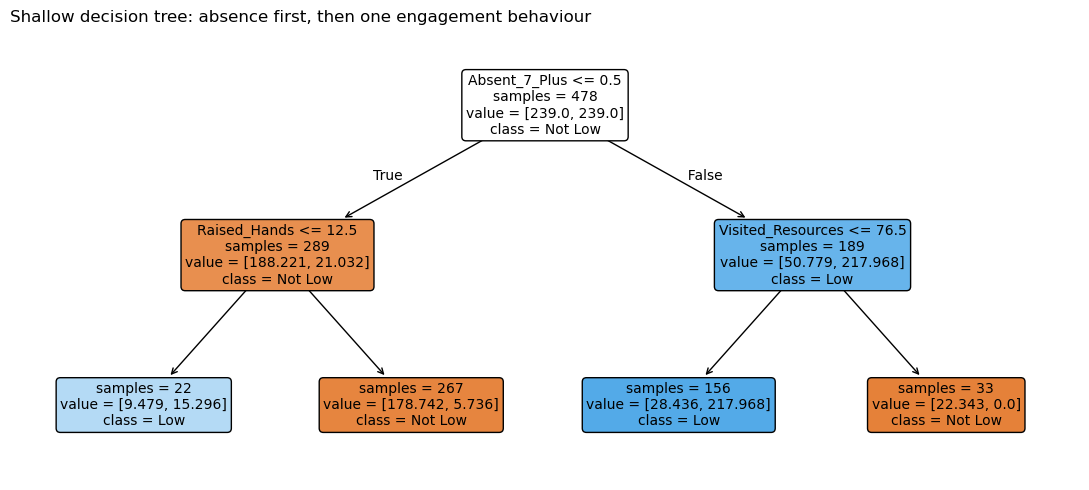

In [16]:
# Cell 4b: Draw the decision tree
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(
    tree_model,
    feature_names=feature_cols,
    class_names=["Not Low", "Low"],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=False,
    fontsize=10,
    ax=ax,
)
ax.set_title("Shallow decision tree: absence first, then one engagement behaviour", loc="left")
plt.tight_layout()
fig.savefig("../reports/decision_tree.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Which signals matter in the logistic model?
Coefficients are on a standardised scale, so their sizes can be compared.
Positive = higher Low risk; negative = lower Low risk.

Visited_Resources      -1.11
Announcements_Viewed   -0.81
Raised_Hands           -0.77
Discussion_Posts       -0.40
Absent_7_Plus           1.52
dtype: float64


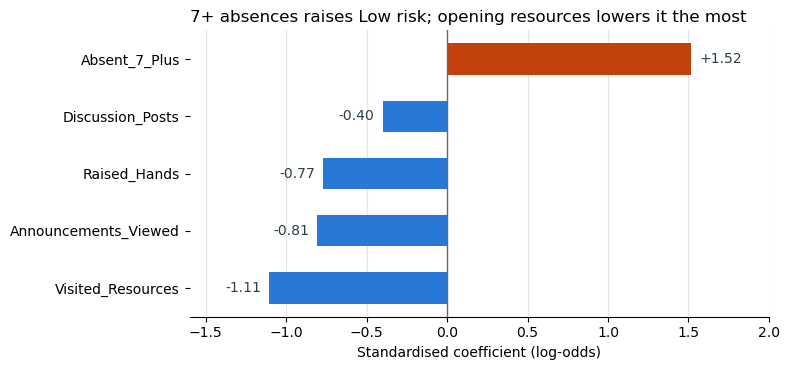

In [15]:
# Cell 5: Fit on all records and read the standardised coefficients
log_model.fit(X, y)
coefs = pd.Series(log_model[-1].coef_[0], index=feature_cols).sort_values()

print(coefs.round(2))

colors = ["#c2410c" if c > 0 else "#2a78d6" for c in coefs]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(coefs.index, coefs.values, color=colors, height=0.55)
ax.axvline(0, color="#5F6B72", linewidth=1)
for i, v in enumerate(coefs.values):
    ax.text(v + (0.05 if v > 0 else -0.05), i, f"{v:+.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=10, color="#2D3E46")
ax.set_title("7+ absences raises Low risk; opening resources lowers it the most", loc="left")
ax.set_xlabel("Standardised coefficient (log-odds)")
ax.set_xlim(-1.6, 2.0)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
fig.savefig("../reports/logistic_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()